# Bước 09 — Trực quan hóa kiểm chứng phương án A

**Mục tiêu:** trình bày đúng kết quả Test cho từng mã–ngày, không huấn luyện lại mô hình, không đổi ngưỡng Q99, không dùng Proxy P0 để sửa nhãn.

**Năm nhóm biểu đồ đã thống nhất**:
1. Timeline từng mã (13 hình + bản xem nhanh); 2. Feature Signature Heatmap; 3. Consensus & Overlap Matrix; 4. ROC và PR so với P0; 5. Phân phối điểm Val-calibrate so với Test.

Thêm **8 hình OHLCV** cho các trường hợp đã được chọn bằng quy tắc rõ ràng, không tạo hàng loạt hình không cần thiết.

Đặt notebook trong `Stocks/notebooks/`, cùng cấp thư mục `outputs/`. Chọn cùng môi trường đã dùng ở Bước 08 rồi **Restart Kernel → Run All**. Tất cả đầu vào được xác định và kiểm tra trước khi vẽ; thiếu file sẽ báo tên rõ ràng. Dự đoán Bước 08 không bị ghi đè.

## Ô 1 — Thư viện và cấu hình nghiên cứu cố định

In [1]:
# -*- coding: utf-8 -*-
"""
Bước 09 — Trực quan hóa có hệ thống kết quả phương án A (Thí nghiệm 1).
Mục tiêu: mô tả kết quả Test đã khóa, KHÔNG huấn luyện lại/chọn lại ngưỡng.
Đầu vào trong Stocks/notebooks/outputs:
  03_feature_engineering/03_features_all.csv
  07_threshold_calibration_A/07_calibration_scores.csv
  07_threshold_calibration_A/07_thresholds.json
  07_P0_final_pretest_A/07_A_P0_frozen_policy.json
  08_test_evaluation_A/08_test_predictions_A.csv
  08_test_evaluation_A/08_test_QA_manifest.json
Đầu ra: outputs/09_final_evaluation_A/figures/, tables/ và báo cáo.
"""

from __future__ import annotations
import os
import json
import hashlib
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import TwoSlopeNorm, Normalize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, roc_auc_score

FEATURES = ['z_gap', 'z_intraday', 'z_range', 'z_volume']
MODELS = ['IF', 'AE', 'LOF']
COLORS = {'IF': '#21618C', 'AE': '#C06B36', 'LOF': '#3B806A'}
ALERT = '#C54644'
BACKGROUND = '#F3F6F9'

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'figure.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'savefig.facecolor': 'white',
    'savefig.bbox': 'tight',
})

## Ô 2 — Kiểm tra nguồn, ngưỡng Q99 và tính Proxy P0 từ lịch sử

In [2]:
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def find_project_root() -> Path:
    if os.environ.get('EXP1_ROOT'):
        root = Path(os.environ['EXP1_ROOT']).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f'EXP1_ROOT không tồn tại: {root}')
        return root
    # Tương thích khi chạy Python và Jupyter trong Stocks/notebooks.
    here = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
    for candidate in [here, here / 'notebooks', *here.parents, Path.cwd(), Path.cwd() / 'notebooks', *Path.cwd().parents]:
        if (candidate / 'outputs' / '08_test_evaluation_A' / '08_test_predictions_A.csv').is_file():
            return candidate
    # Hỗ trợ tài liệu người dùng gửi trong môi trường làm việc riêng.
    if (here / '08_test_predictions_A(1).csv').exists():
        return here
    raise FileNotFoundError(
        'Không tìm thấy thư mục dự án có outputs/08_test_evaluation_A/08_test_predictions_A.csv. '
        'Đặt script và notebook trong Stocks/notebooks/ hoặc đặt biến EXP1_ROOT.'
    )


def need(root: Path, rel: str, fallback: tuple[str, ...] = ()) -> Path:
    candidates = [root / rel, *(root / v for v in fallback)]
    for p in candidates:
        if p.is_file():
            return p
    raise FileNotFoundError('Thiếu file đầu vào bắt buộc: ' + ' | '.join(map(str, candidates)))


def read_json(path: Path) -> dict:
    with path.open('r', encoding='utf-8') as file:
        return json.load(file)


def assert_test_integrity(test: pd.DataFrame, cal: pd.DataFrame, all_features: pd.DataFrame,
                          threshold_manifest: dict, policy: dict, qa: dict, sources: dict) -> dict:
    assert len(test) == 2405, f'Test có {len(test)} phiên, khác 2405.'
    assert test.ticker.nunique() == 13, 'Test không đủ 13 mã.'
    assert test.date.nunique() == 185, 'Test không đủ 185 ngày.'
    assert (str(test.date.min()), str(test.date.max())) == ('2025-12-24', '2026-09-25')
    assert not test.duplicated(['ticker', 'date']).any(), 'Trùng mã và ngày trong Test.'
    assert not cal.duplicated(['ticker','date']).any()
    assert len(cal) == 962, 'Val-calibrate khác 962.'
    assert test[FEATURES + [f'score_{m.lower()}' for m in MODELS]].notna().all().all()
    assert np.isfinite(test[FEATURES + [f'score_{m.lower()}' for m in MODELS]].to_numpy(float)).all()
    assert all(c in all_features.columns for c in ['split','is_model_ready',*FEATURES])
    assert set(threshold_manifest['feature_cols']) == set(FEATURES)
    assert threshold_manifest['feature_cols'] == FEATURES
    assert threshold_manifest['quantile'] == 0.99
    assert threshold_manifest['rule'] == 'score > threshold'
    assert policy['model_features'] == FEATURES
    assert policy['proxy_name'] == 'P0_final_std20_mean20_OR'
    assert qa['no_model_refit'] and qa['no_threshold_recalibration_on_test']
    assert not qa['proxy_p0_used_in_scoring']
    assert sha256(sources['test']) == qa['output_predictions_sha256'], 'File Test bị thay đổi sau Bước 08.'
    assert sha256(sources['features']) == policy['feature_data_sha256'], 'Dữ liệu đặc trưng sai phiên bản.'
    assert sha256(sources['thresholds']) == policy['step07_threshold_manifest_sha256'], 'Ngưỡng sai phiên bản.'
    assert qa['model_sha256'] == policy['model_sha256'], 'Checkpoint giữa Bước 07 và 08 không nhất quán.'
    assert (cal['date'].min() < test['date'].min()) and (cal['date'].max() < test['date'].min()), 'Chia thời gian bị sai.'
    test_for_check = all_features.loc[(all_features['split'] == 'test') & (all_features['is_model_ready'].astype(bool)),
                                       ['ticker','date','open','high','low','close','volume',*FEATURES]]
    paired = test.merge(test_for_check, on=['ticker','date'], how='left', validate='one_to_one', suffixes=('', '_source'))
    assert len(paired) == 2405 and paired[[f'{FEATURES[0]}_source']].notna().all().all()
    for field in ['open','high','low','close','volume',*FEATURES]:
        delta = np.max(np.abs(paired[field].astype(float) - paired[f'{field}_source'].astype(float)))
        assert delta < 1e-9, f'{field} của Test không khớp Bước 03; chênh lớn nhất {delta}'
    summary = {}
    for model in MODELS:
        s_col = f'score_{model.lower()}'
        pred_col = f'{model.lower()}_prediction'
        threshold = float(threshold_manifest['thresholds'][model]['threshold'])
        saved_val = float(policy['thresholds'][model])
        assert abs(threshold - saved_val) < 1e-12
        cal_q99 = float(np.quantile(cal[s_col].to_numpy(float), 0.99, method='linear'))
        assert abs(threshold - cal_q99) < 1e-8, f'Ngưỡng {model} không tái lập Val-cal.'
        recomputed = (test[s_col].to_numpy(float) > threshold).astype(int)
        assert np.array_equal(test[pred_col].to_numpy(int), recomputed), f'Nhãn {model} không đúng Q99.'
        summary[model] = {'threshold':threshold, 'n_test_alerts':int(recomputed.sum())}
    assert all(int(test[f'{m.lower()}_prediction'].sum()) == v for m, v in [('IF',13),('AE',21),('LOF',31)])
    flag = test[[f'{m.lower()}_prediction' for m in MODELS]].to_numpy(int)
    assert int((flag.sum(axis=1)>0).sum()) == 48 and int((flag.sum(axis=1)==3).sum()) == 4
    return summary


def make_proxy(all_features: pd.DataFrame) -> pd.DataFrame:
    x = (all_features[['ticker','date','close','volume','split']]
         .copy().sort_values(['ticker','date']).reset_index(drop=True))
    assert (x.close > 0).all() and (x.volume > 0).all()
    assert not x.duplicated(['ticker','date']).any()
    groups = x.groupby('ticker', sort=False)
    x['close_prev'] = groups['close'].shift(1)
    x['return_cc'] = np.log(x['close'] / x['close_prev'])
    x['std20_prior_return'] = x.groupby('ticker', sort=False)['return_cc'].transform(
        lambda s: s.shift(1).rolling(20, min_periods=20).std(ddof=1))
    x['mean20_prior_volume'] = x.groupby('ticker', sort=False)['volume'].transform(
        lambda s: s.shift(1).rolling(20, min_periods=20).mean())
    x['proxy_eligible'] = x[['return_cc','std20_prior_return','mean20_prior_volume']].notna().all(axis=1)
    x['proxy_price'] = x['proxy_eligible'] & (x['return_cc'].abs() > 2*x['std20_prior_return'])
    x['proxy_volume'] = x['proxy_eligible'] & (x['volume'] > 3*x['mean20_prior_volume'])
    x['proxy_joint'] = x['proxy_price'] & x['proxy_volume']
    x['proxy_label'] = np.where(x['proxy_eligible'], (x['proxy_price'] | x['proxy_volume']).astype(int), -1)
    return x


def save_figure(fig: plt.Figure, dest: Path) -> None:
    dest.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(dest, dpi=175, bbox_inches='tight', pad_inches=0.16)
    plt.close(fig)

## Ô 3 — Hàm vẽ biểu đồ có mục tiêu nghiên cứu riêng

In [3]:
def company_timelines(test: pd.DataFrame, threshold: float, out: Path):
    ticker_list = sorted(test.ticker.unique())
    lo = min(0.32, float(test.score_if.min())-0.016)
    hi = max(0.80, float(test.score_if.max())+0.02)
    out.mkdir(parents=True,exist_ok=True)
    result = []
    for ticker in ticker_list:
        v = test.loc[test.ticker==ticker].copy().sort_values('date')
        dates = pd.to_datetime(v.date)
        flag = v.if_prediction.eq(1)
        fig, ax = plt.subplots(figsize=(13.6, 4.0))
        ax.plot(dates, v.score_if, color=COLORS['IF'], linewidth=1.6, alpha=0.88,
                label='Điểm Isolation Forest')
        ax.scatter(dates[flag], v.loc[flag,'score_if'], color=ALERT, edgecolor='white', linewidth=0.9,
                   s=64, zorder=5, label='Phiên IF cảnh báo')
        ax.axhline(threshold, color=ALERT, ls='--', lw=1.6,
                   label=f'Ngưỡng Q99 cố định = {threshold:.4f}')
        ax.set_ylim(lo, hi)
        ax.set_xlim(pd.Timestamp('2025-12-19'), pd.Timestamp('2026-09-30'))
        ax.set_ylabel('IF Anomaly Score')
        ax.set_xlabel('Ngày giao dịch (Test)')
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
        ax.grid(axis='y',color='#DCE4EB', lw=0.6)
        ax.set_title(f'{ticker} | Dòng thời gian điểm IF — {int(flag.sum())} phiên cảnh báo / {len(v)} phiên',
                     loc='left', fontweight='bold', pad=14)
        if int(flag.sum())==0:
            ax.text(0.5,0.93,'Không có phiên vượt Q99 trong Test', transform=ax.transAxes,
                    ha='center',va='top',color='#667085',fontsize=10)
        if 0 < flag.sum() <= 3:
            for date, score in zip(dates[flag], v.loc[flag,'score_if']):
                ax.annotate(date.strftime('%d/%m'),(date,score),xytext=(0,11),
                            textcoords='offset points', ha='center', fontsize=8,color=ALERT)
        ax.legend(loc='upper left',fontsize=8,frameon=False,ncol=3,bbox_to_anchor=(0,-0.25))
        p = out / f'09_timeline_{ticker}.png'
        save_figure(fig,p)
        result.append({'ticker':ticker,'n_sessions':int(len(v)),'if_alerts':int(flag.sum()),'figure':p.name})

    # Bản mục lục nhỏ — cùng một loại biểu đồ, không tạo thêm phép đánh giá.
    fig, axs = plt.subplots(4,4,figsize=(18.5,11.8),sharey=True,sharex=True)
    for ax in axs.flat:
        ax.set_visible(False)
    for ax,ticker in zip(axs.flat,ticker_list):
        ax.set_visible(True)
        v=test.loc[test.ticker==ticker].sort_values('date')
        date=pd.to_datetime(v.date); sel=v.if_prediction.eq(1)
        ax.plot(date,v.score_if,color=COLORS['IF'],lw=1.2,alpha=.86)
        ax.scatter(date[sel],v.loc[sel,'score_if'],s=27,color=ALERT,zorder=3)
        ax.axhline(threshold,color=ALERT,lw=1,ls='--')
        ax.set_ylim(lo,hi)
        ax.set_title(f'{ticker} · {int(sel.sum())} cảnh báo',fontsize=10,fontweight='bold',loc='left')
        ax.grid(axis='y',color='#E4EAF0',lw=0.5)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
        ax.tick_params(axis='both',labelsize=8)
    fig.suptitle('13 cổ phiếu HOSE | IF Anomaly Score theo thời gian Test (Q99 cố định)',
                 fontsize=15,fontweight='bold',y=0.99)
    fig.text(.5,.01,'Chấm đỏ = IF dự đoán bất thường | Đường đứt = ngưỡng Q99',ha='center',fontsize=10,color='#566372')
    fig.tight_layout(rect=(0,.025,1,.975),h_pad=2.0)
    overview=out / '09_timelines_13_tickers_overview.png'
    save_figure(fig,overview)
    return pd.DataFrame(result),overview


def feature_signature(test: pd.DataFrame, out: Path) -> Path:
    alerts=test.loc[test.if_prediction.eq(1)].copy().sort_values('score_if',ascending=False)
    assert len(alerts)==13
    values=alerts[FEATURES].to_numpy(float)
    clip=10.0
    f, (ax,ax2)=plt.subplots(1,2,figsize=(12.8,7.8),gridspec_kw={'width_ratios':[4.2,2.3]})
    heat=ax.imshow(np.clip(values,-clip,clip),cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-clip,vcenter=0,vmax=clip),aspect='auto')
    ax.set_xticks(range(4),['Gap','Intraday','Range','Volume'])
    labels=[f"{row.ticker}  {pd.Timestamp(row.date).strftime('%d/%m/%Y')}" for row in alerts.itertuples()]
    ax.set_yticks(range(13), labels)
    for i in range(13):
        for j in range(4):
            v=values[i,j]
            ax.text(j,i,f'{v:+.1f}',ha='center',va='center',fontsize=9,
                    color='white' if abs(v)>=6.8 else '#1B2934',fontweight='bold' if abs(v)>=6.8 else 'normal')
    ax.set_title('Dấu hiệu bốn đặc trưng của 13 phiên IF cảnh báo',fontweight='bold',loc='left',pad=13)
    cb=f.colorbar(heat,ax=ax,shrink=0.82,pad=.03)
    cb.set_label('Giá trị z hiển thị giới hạn màu ±10')
    flags=alerts[['ae_prediction','lof_prediction','proxy_label']].to_numpy(int)
    ax2.imshow(flags,cmap=matplotlib.colors.ListedColormap(['#EEF1F5','#3B806A']),vmin=0,vmax=1,aspect='auto')
    ax2.set_xticks(range(3),['AE','LOF','Proxy P0'])
    ax2.set_yticks(range(13),[])
    for i in range(13):
        for j in range(3):
            ax2.text(j,i,('Có' if flags[i,j] else '—'),color='white' if flags[i,j] else '#667085',
                     ha='center',va='center',fontsize=9,fontweight='bold' if flags[i,j] else 'normal')
    ax2.set_title('Đối chiếu cùng phiên',fontweight='bold',pad=13)
    f.text(0.06,0.015,'Màu cho biết dấu/mức độ của đặc trưng; KHÔNG phải độ quan trọng hay đóng góp của đặc trưng vào IF. Số trong ô là z gốc.',
           fontsize=9,color='#475569')
    f.tight_layout(rect=(0,.035,1,1))
    dest=out/'09_feature_signature_IF13.png'
    save_figure(f,dest)
    return dest


def consensus_matrix(test: pd.DataFrame,out:Path):
    sets={m:set(map(tuple,test.loc[test[f'{m.lower()}_prediction'].eq(1),['ticker','date']].to_numpy())) for m in MODELS}
    n=np.zeros((3,3),int); jacc=np.zeros((3,3))
    rows=[]
    for i,m in enumerate(MODELS):
        for k,other in enumerate(MODELS):
            common=len(sets[m]&sets[other]); union=len(sets[m]|sets[other])
            n[i,k]=common; jacc[i,k]=common/union if union else np.nan
            if i<k:
                rows.append({'model_a':m,'model_b':other,'n_a':len(sets[m]),'n_b':len(sets[other]),
                             'intersection':common,'union':union,'jaccard':jacc[i,k]})
    f,ax=plt.subplots(figsize=(8.3,6.9))
    colors=jacc.copy()
    np.fill_diagonal(colors,0)
    im=ax.imshow(colors,cmap='Blues',vmin=0,vmax=.55)
    ax.set_xticks(range(3),MODELS,fontsize=12)
    ax.set_yticks(range(3),MODELS,fontsize=12)
    for i in range(3):
        for k in range(3):
            if i==k:
                text=f'{n[i,k]} cảnh báo\n(tập {MODELS[i]})'
                ax.add_patch(Rectangle((k-.5,i-.5),1,1,fill=True,color='#E9EEF3',zorder=2))
                ax.text(k,i,text,ha='center',va='center',color='#243445',fontweight='bold',fontsize=11,zorder=3)
            else:
                ax.text(k,i,f'{n[i,k]} phiên chung\nJaccard {jacc[i,k]*100:.1f}%',ha='center',va='center',
                        color='#ffffff' if jacc[i,k]>.33 else '#203040',fontsize=11,fontweight='bold')
    for x in np.arange(-.5,3,1):
        ax.axhline(x,color='white',lw=2);ax.axvline(x,color='white',lw=2)
    ax.set_title('Consensus & Overlap — chỉ xét phiên được cảnh báo (Test)',fontweight='bold',pad=17)
    ax.text(.5,-.17,'48 phiên được ít nhất một mô hình cảnh báo  |  4 phiên được cả ba cảnh báo',
            transform=ax.transAxes,ha='center',fontsize=10,color='#586879')
    cb=f.colorbar(im,ax=ax,shrink=.7,pad=.03)
    cb.set_label('Jaccard cặp mô hình (ngoài đường chéo)')
    f.tight_layout()
    dest=out/'09_consensus_overlap_matrix.png'
    save_figure(f,dest)
    return pd.DataFrame(rows),dest


def roc_pr_figures(x:pd.DataFrame, out:Path, prior_figs:Path|None = None):
    metrics=[]; curves={}
    y=x.proxy_label.to_numpy(int)
    assert set(y)=={0,1}
    for m in MODELS:
        score=x[f'score_{m.lower()}'].to_numpy(float)
        fpr,tpr,_=roc_curve(y,score)
        pr,re,_=precision_recall_curve(y,score)
        score_roc=float(roc_auc_score(y,score))
        ap=float(average_precision_score(y,score))
        pr_area=float(auc(re,pr))
        metrics.append({'model':m,'n_test':len(y),'p0_positive':int(y.sum()),
                        'roc_auc_vs_P0':score_roc,'average_precision_vs_P0':ap,
                        'pr_auc_trapezoid_vs_P0':pr_area})
        curves[m]=dict(fpr=fpr,tpr=tpr,precision=pr,recall=re)
    metrics_df=pd.DataFrame(metrics)
    files={}
    for kind in ['ROC','PR']:
        out_path=out/f'09_{kind}_vs_P0.png'
        maybe=prior_figs / f'09_test_{kind}_vs_P0.png' if prior_figs else None
        old_table=prior_figs/'09_model_metrics_vs_P0.csv' if prior_figs else None
        valid_legacy=False
        if maybe is not None and maybe.is_file() and old_table.is_file():
            check=pd.read_csv(old_table).set_index('model')
            col = 'roc_auc_vs_proxy' if kind=='ROC' else 'average_precision_vs_proxy'
            valid_legacy = all(abs(float(check.loc[m,col]) - float(metrics_df.set_index('model').loc[m, 'roc_auc_vs_P0' if kind=='ROC' else 'average_precision_vs_P0'])) < 1e-8 for m in MODELS)
        if valid_legacy:
            shutil.copy2(maybe,out_path)
            files[kind]=(out_path,'Giữ nguyên biểu đồ đã có ở Bước 09')
            continue
        f,ax=plt.subplots(figsize=(8.9,6.5))
        for m in MODELS:
            row=metrics_df.set_index('model').loc[m]
            if kind=='ROC':
                ax.plot(curves[m]['fpr'],curves[m]['tpr'],lw=2.2,color=COLORS[m],label=f'{m} | ROC-AUC={row.roc_auc_vs_P0:.3f}')
            else:
                ax.plot(curves[m]['recall'],curves[m]['precision'],lw=2.2,color=COLORS[m],label=f'{m} | AP={row.average_precision_vs_P0:.3f}')
        if kind=='ROC':
            ax.plot([0,1],[0,1],'--',color='#9AA6B3',lw=1.3,label='Ngẫu nhiên')
            ax.set(xlabel='Tỷ lệ dương giả so với P0',ylabel='Tỷ lệ dương đúng so với P0',title='ROC Curve — điểm liên tục so với Proxy P0 (Test)')
        else:
            ax.axhline(float(y.mean()),ls='--',color='#9AA6B3',lw=1.3,label=f'Tỷ lệ P0=1: {y.mean()*100:.2f}%')
            ax.set(xlabel='Recall so với P0',ylabel='Precision so với P0',title='Precision–Recall — điểm liên tục so với Proxy P0 (Test)')
        ax.set_xlim(0,1);ax.set_ylim(0,1.02)
        ax.grid(alpha=.2);ax.legend(loc='best',fontsize=10,frameon=False)
        f.tight_layout()
        save_figure(f,out_path)
        files[kind]=(out_path,'Tạo mới vì chưa có biểu đồ Bước 09 hợp lệ ở local')
    return metrics_df,files


def score_distribution(cal:pd.DataFrame,test:pd.DataFrame,out:Path):
    f,axs=plt.subplots(1,3,figsize=(15.7,4.6))
    rows=[]
    for ax,m in zip(axs,MODELS):
        col=f'score_{m.lower()}'
        values_cal=cal[col].to_numpy(float)
        values_test=test[col].to_numpy(float)
        transform=(lambda arr:np.log1p(arr)) if m=='AE' else (lambda arr:arr)
        a,b=transform(values_cal),transform(values_test)
        bins=np.histogram_bin_edges(np.concatenate([a,b]),bins=36)
        ax.hist(a,bins=bins,density=True,histtype='step',linewidth=1.9,
                color='#7B8DA5',label=f'Val-cal (n={len(a)})')
        ax.hist(b,bins=bins,density=True,histtype='step',linewidth=1.9,
                color=COLORS[m],label=f'Test (n={len(b)})')
        ax.set_title(f'{m} | Phân phối điểm',fontsize=12,fontweight='bold')
        ax.set_xlabel('log(1 + AE Score)' if m=='AE' else f'{m} Anomaly Score')
        ax.set_ylabel('Mật độ')
        ax.grid(alpha=.17,axis='y');ax.legend(frameon=False,fontsize=9)
        for name,vec in [('Val-cal',values_cal),('Test',values_test)]:
            rows.append({'model':m,'period':name,'n':len(vec),
                         'median':float(np.median(vec)),'q90':float(np.quantile(vec,.9)),
                         'q95':float(np.quantile(vec,.95)),'q99':float(np.quantile(vec,.99)),
                         'max':float(np.max(vec))})
    f.suptitle('Phân phối Anomaly Score: Val-calibrate vs Test — không đặt ngưỡng trên hình',
               fontsize=14,fontweight='bold',y=1.06)
    f.text(.5,-.055,'Mỗi mô hình có thang điểm riêng; riêng AE hiển thị trục log(1+score) để thấy rõ đuôi dài.',
           ha='center',fontsize=9,color='#64748B')
    f.tight_layout()
    dest=out/'09_score_distributions_valcal_vs_test.png'
    save_figure(f,dest)
    return pd.DataFrame(rows),dest


def pick_review_cases(x:pd.DataFrame) -> pd.DataFrame:
    # 2 phiên IF=1 nhưng P0=0, 4 phiên cả 3 đồng thuận,
    # 2 phiên P0=1 nhưng IF=0 (1 price-only + 1 volume-only) ở sát ngưỡng IF.
    choices=[]
    for row in x.loc[(x.if_prediction==1)&(x.proxy_label==0)].sort_values(['date','ticker']).itertuples():
        choices.append({'ticker':row.ticker,'date':row.date,'case_group':'IF=1, P0=0','selection_rule':'Tất cả phiên IF cảnh báo ngoài P0'})
    for row in x.loc[(x.if_prediction==1)&(x.ae_prediction==1)&(x.lof_prediction==1)].sort_values(['date','ticker']).itertuples():
        choices.append({'ticker':row.ticker,'date':row.date,'case_group':'IF=AE=LOF=1','selection_rule':'Tất cả phiên ba mô hình cùng cảnh báo'})
    fallback=x.loc[(x.proxy_label==1)&(x.if_prediction==0)].copy()
    price=fallback.loc[(fallback.proxy_price)&(~fallback.proxy_volume)].sort_values('score_if',ascending=False)
    volume=fallback.loc[(fallback.proxy_volume)&(~fallback.proxy_price)].sort_values('score_if',ascending=False)
    for table,label in [(price,'P0 price-only, IF=0'),(volume,'P0 volume-only, IF=0')]:
        if len(table):
            row=table.iloc[0]
            choices.append({'ticker':row.ticker,'date':row.date,'case_group':label,
                            'selection_rule':'Phiên P0-only có điểm IF cao nhất trong nhóm điều kiện'})
    out=pd.DataFrame(choices).drop_duplicates(['ticker','date'])
    if len(out)<8:
        keys=set(map(tuple,out[['ticker','date']].to_numpy()))
        for row in fallback.sort_values('score_if',ascending=False).itertuples():
            if (row.ticker,row.date) not in keys:
                out=pd.concat([out,pd.DataFrame([{'ticker':row.ticker,'date':row.date,
                       'case_group':'P0=1, IF=0 (bổ sung)','selection_rule':'Điểm IF cao nhất còn lại'}])],ignore_index=True)
                keys.add((row.ticker,row.date))
            if len(out)>=8:break
    assert len(out)==8 and not out.duplicated(['ticker','date']).any(), 'Bộ mẫu cần đúng 8 phiên khác nhau.'
    return out.merge(x,on=['ticker','date'],how='left',validate='one_to_one')


def candle_volume_for_cases(cases:pd.DataFrame, full:pd.DataFrame, out:Path):
    out.mkdir(parents=True,exist_ok=True)
    plots=[]
    full=full[['ticker','date','open','high','low','close','volume']].sort_values(['ticker','date'])
    for row in cases.itertuples():
        selected=full.loc[(full.ticker==row.ticker)&(full.date<=row.date)].tail(61).copy()
        assert len(selected)==61 and selected.iloc[-1].date==row.date, f'Thiếu 60 phiên trước của {row.ticker} {row.date}'
        selected=selected.reset_index(drop=True)
        idx=np.arange(len(selected))
        rising=selected.close>=selected.open
        bar_colors=np.where(rising,'#31886C','#C04D4B')
        f, (ax,vol)=plt.subplots(2,1,figsize=(12.5,6.2),sharex=True,
                                 gridspec_kw={'height_ratios':[3.2,1.1],'hspace':.09})
        body_width=.6
        for i,r in enumerate(selected.itertuples()):
            ax.vlines(i,r.low,r.high,color=bar_colors[i],lw=1.1,zorder=2)
            height=abs(r.close-r.open)
            baseline=min(r.open,r.close)
            if height<1e-7:
                ax.hlines(r.open,i-.3,i+.3,color=bar_colors[i],lw=1.2,zorder=3)
            else:
                ax.add_patch(Rectangle((i-body_width/2,baseline),body_width,height,
                                       facecolor=bar_colors[i],edgecolor=bar_colors[i],lw=.4))
        ax.axvspan(59.5,60.5,color='#F0BB77',alpha=.2,zorder=0)
        ax.axvline(60,color='#B5792C',lw=1.1,ls='--')
        vol.bar(idx,selected.volume/1e6,color=bar_colors,alpha=.78,width=.76)
        vol.axvspan(59.5,60.5,color='#F0BB77',alpha=.2)
        vol.axvline(60,color='#B5792C',lw=1.1,ls='--')
        ax.set_ylabel('Giá OHLC (đơn vị gốc)')
        vol.set_ylabel('Volume (triệu)')
        vol.set_xlabel('60 phiên trước + phiên đang xét, đúng thứ tự thời gian')
        tick_positions=list(range(0,61,10))
        vol.set_xticks(tick_positions)
        vol.set_xticklabels([pd.Timestamp(selected.iloc[i].date).strftime('%d/%m/%y') for i in tick_positions],rotation=0,fontsize=9)
        for panel in [ax,vol]:panel.grid(axis='y',alpha=.16)
        ax.set_title(f"{row.ticker} — {pd.Timestamp(row.date).strftime('%d/%m/%Y')} | {row.case_group}",
                     loc='left',fontsize=13,fontweight='bold',pad=12)
        ax.text(.01,.98,f'IF={row.score_if:.4f} (nhãn {int(row.if_prediction)})  |  AE={int(row.ae_prediction)}  |  LOF={int(row.lof_prediction)}  |  P0={int(row.proxy_label)}',
                transform=ax.transAxes,va='top',fontsize=9,color='#334155',
                bbox={'boxstyle':'round,pad=.3','facecolor':'white','edgecolor':'#DFE6ED','alpha':.92})
        f.text(.5,.005,'Chỉ dùng OHLCV của phiên hiện tại và 60 phiên trước; không dùng tin tức hoặc phiên tương lai.',
               ha='center',color='#667085',fontsize=9)
        f.subplots_adjust(left=.085,right=.985,top=.89,bottom=.17)
        dest=out/f'09_case_{row.ticker}_{row.date}.png'
        save_figure(f,dest)
        plots.append({'ticker':row.ticker,'date':row.date,'case_group':row.case_group,'figure':dest.name})
    return pd.DataFrame(plots)


def write_summary(root:Path, path:Path, files:dict, test:pd.DataFrame, x:pd.DataFrame,
                  metrics:pd.DataFrame, overlap:pd.DataFrame, distribution:pd.DataFrame,
                  tickers:pd.DataFrame, cases:pd.DataFrame, threshold_info:dict) -> str:
    model_count={m:int(test[f'{m.lower()}_prediction'].sum()) for m in MODELS}
    overlap_str=' | '.join(f'{r.model_a}–{r.model_b}: {r.intersection} phiên, Jaccard {100*r.jaccard:.2f}%' for r in overlap.itertuples())
    lines=[
        '# Bước 09 — Trực quan hóa kiểm chứng phương án A (dữ liệu Test)', '',
        '## Phạm vi và tính toàn vẹn',
        f'- Test: **{len(test):,} mã–ngày**, **{test.ticker.nunique()} mã**, {test.date.nunique()} ngày, {test.date.min()} đến {test.date.max()}.',
        f"- Ngưỡng IF Q99 cố định = **{threshold_info['IF']['threshold']:.9f}**, lấy trên Val-calibrate; không fit lại.",
        f"- IF: **{model_count['IF']}** phiên; AE: **{model_count['AE']}**; LOF: **{model_count['LOF']}**.",
        '- Đối chiếu SHA-256, đặc trưng và nhãn 0/1 với file Bước 08: **đạt**.',
        '- P0 chỉ dùng đánh giá; không ảnh hưởng dự đoán/score của IF, AE, LOF.', '',
        '## Năm nhóm hình có mục đích riêng',
        '1. **13 timeline IF:** mã nào, phiên nào vượt Q99; kể cả những mã không có cảnh báo. Có thêm một bản tổng quan dạng mục lục.',
        '2. **Feature Signature:** bốn giá trị z của chính 13 phiên IF=1; màu không biểu thị feature importance.',
        '3. **Consensus & Overlap Matrix:** số phiên đồng thuận IF/AE/LOF, Jaccard chỉ trên tập có cảnh báo.',
        '4. **ROC/PR:** điểm liên tục so với P0, KHÔNG sử dụng Q99; dùng lại hình hiện có nếu kiểm chứng hợp lệ.',
        '5. **Score Distribution:** đối chiếu Val-calibrate và Test theo từng mô hình, không đặt đường ngưỡng; mỗi mô hình có thang riêng.',
        'Nhóm biểu đồ nến/khối lượng chỉ dành cho 8 trường hợp đã được chọn theo quy tắc cố định, không vẽ đại trà.', '',
        '## Những con số cần hiểu đúng',
        f'- Các cặp đồng thuận: {overlap_str}.',
        f'- Cả ba cùng cảnh báo: **{int((test[["if_prediction","ae_prediction","lof_prediction"]].sum(axis=1)==3).sum())}** phiên.',
        f'- Có ít nhất một mô hình cảnh báo: **{int((test[["if_prediction","ae_prediction","lof_prediction"]].sum(axis=1)>0).sum())}** phiên.',
        f'- Trong 13 cảnh báo IF, **{int((x.loc[x.if_prediction==1, "z_range"]>5).sum())}/13 phiên có z_range > 5**; đây là mốc mô tả mức rộng biên độ, KHÔNG phải quy tắc gán nhãn hay feature importance.',
        f'- Proxy P0=1: **{int(x.proxy_label.sum())} / {len(x)}** phiên; P0 đo return close-to-close và khối lượng tăng, không bao quát mọi kiểu bất thường OHLCV.',
    ]
    for row in metrics.itertuples():
        lines.append(f'- {row.model}: ROC-AUC với P0 **{row.roc_auc_vs_P0:.4f}**, AP **{row.average_precision_vs_P0:.4f}** (KHÔNG phải độ chính xác với nhãn thật).')
    lines += ['', '## Điều không được suy luận',
              '- Điểm IF cao hoặc vượt Q99 không xác nhận một phiên chắc chắn bất thường thật.',
              '- IF/AE/LOF đồng thuận không phải bằng chứng ba mô hình đều đúng.',
              '- Cùng P0 không chứng minh chính xác; P0 có phạm vi hẹp hơn bốn đặc trưng của mô hình.',
              '- Sự dịch chuyển phân bố điểm giữa hai giai đoạn không tự chứng minh mô hình suy giảm hay lỗi dữ liệu.',
              '- Không được thay ngưỡng/mô hình dựa trên Test vừa quan sát.', '',
              '## Mẫu phiên OHLCV được vẽ',
              '- 2 phiên IF=1, P0=0 (toàn bộ nhóm bất đồng này).',
              '- 4 phiên IF=AE=LOF=1 (toàn bộ nhóm ba mô hình đồng thuận).',
              '- 2 phiên P0=1, IF=0: ưu tiên một price-only và một volume-only có điểm IF cao nhất trong nhóm, để đối chiếu sát quyết định.',
              '- Mỗi hình chỉ dùng 60 phiên trước và phiên đang xét, không thêm tin tức hay dữ liệu tương lai.', '',
              '## Bảng đầu ra',
              '- `tables/09_proxy_on_test.csv`: P0 được tính lại từ OHLCV, ghép với điểm Test.',
              '- `tables/09_model_roc_pr_metrics.csv`: ROC-AUC / AP từ điểm liên tục.',
              '- `tables/09_pairwise_consensus.csv`: giao nhau và Jaccard giữa ba mô hình.',
              '- `tables/09_company_alert_counts.csv`: số cảnh báo theo 13 mã.',
              '- `tables/09_feature_signature_IF13.csv`: đặc trưng 13 phiên IF cảnh báo.',
              '- `tables/09_selected_OHLCV_cases.csv`: quy tắc lựa chọn và thông tin 8 phiên rà soát.',
              '- `tables/09_score_distribution_summary.csv`: trung vị và phân vị điểm theo từng tập.',
              '- `09_visualization_QA.json`: các kiểm tra chống sai nguồn và thay đổi Test.', '',
              '## Quyết định phương pháp',
              '**Giữ nguyên A, không thay IF/AE/LOF hay Q99.** Đây là trực quan hóa và đối chiếu kết quả đã khóa; không là phép huấn luyện hay cải thiện mô hình.',
              ]
    path.write_text('\n'.join(lines),encoding='utf-8')
    return '\n'.join(lines)

## Ô 4 — Chạy toàn bộ Bước 09 và kiểm chứng đầu ra

In [4]:
def main():
    root=find_project_root()
    sources={
        'test':need(root,'outputs/08_test_evaluation_A/08_test_predictions_A.csv',('08_test_predictions_A(1).csv',)),
        'features':need(root,'outputs/03_feature_engineering/03_features_all.csv',('03_features_all.csv',)),
        'cal':need(root,'outputs/07_threshold_calibration_A/07_calibration_scores.csv',('07_calibration_scores(1).csv',)),
        'thresholds':need(root,'outputs/07_threshold_calibration_A/07_thresholds.json',('07_thresholds(1).json',)),
        'policy':need(root,'outputs/07_P0_final_pretest_A/07_A_P0_frozen_policy.json',('07_A_P0_frozen_policy(1).json',)),
        'qa':need(root,'outputs/08_test_evaluation_A/08_test_QA_manifest.json',('08_test_QA_manifest(1).json',)),
    }
    out=root/'outputs'/'09_final_evaluation_A'
    figs=out/'figures';tab=out/'tables'
    for p in [figs,tab]:p.mkdir(parents=True,exist_ok=True)
    print('01/08 | Đọc dữ liệu Test, Val-cal, đặc trưng và cấu hình đã khóa...')
    test=pd.read_csv(sources['test']); cal=pd.read_csv(sources['cal']); full=pd.read_csv(sources['features'])
    manifest=read_json(sources['thresholds']);policy=read_json(sources['policy']);qa=read_json(sources['qa'])
    for table in [test,cal,full]:
        table['date']=pd.to_datetime(table['date'],format='%Y-%m-%d',errors='raise').dt.strftime('%Y-%m-%d')
    threshold_info=assert_test_integrity(test,cal,full,manifest,policy,qa,sources)
    print('02/08 | Tính lại Proxy P0 từ lịch sử riêng từng mã (chỉ dùng quá khứ)...')
    proxy=make_proxy(full)
    ptest=proxy.loc[proxy['split']=='test',
         ['ticker','date','return_cc','std20_prior_return','mean20_prior_volume',
          'proxy_eligible','proxy_price','proxy_volume','proxy_joint','proxy_label']].copy()
    x=test.merge(ptest,on=['ticker','date'],how='left',validate='one_to_one')
    assert len(x)==2405 and x.proxy_eligible.all() and set(x.proxy_label)=={0,1}
    assert int(x.proxy_label.sum())==210
    assert int(x.proxy_price.sum())==188 and int(x.proxy_volume.sum())==56 and int(x.proxy_joint.sum())==34
    old_p0=out/'09_test_predictions_with_P0.csv'
    if old_p0.is_file():
        old=pd.read_csv(old_p0)[['ticker','date','proxy_label']]
        assert x[['ticker','date','proxy_label']].merge(old,on=['ticker','date'],how='left',validate='one_to_one',suffixes=('', '_old')).eval('proxy_label == proxy_label_old').all(), 'Proxy trên file cũ Bước 09 khác phiên bản.'
    x.to_csv(tab/'09_proxy_on_test.csv',index=False,encoding='utf-8-sig')
    print('03/08 | Vẽ Timeline cho cả 13 mã, chung thang IF...')
    tickers,overview=company_timelines(x,threshold_info['IF']['threshold'],figs/'01_company_timelines')
    tickers.to_csv(tab/'09_company_alert_counts.csv',index=False,encoding='utf-8-sig')
    print('04/08 | Feature Signature và ma trận đồng thuận...')
    f_feature=feature_signature(x,figs/'02_feature_signature')
    overlap,f_agree=consensus_matrix(x,figs/'03_consensus')
    overlap.to_csv(tab/'09_pairwise_consensus.csv',index=False,encoding='utf-8-sig')
    x.loc[x.if_prediction==1, ['ticker','date',*FEATURES,'score_if','if_prediction','ae_prediction','lof_prediction','proxy_label']].sort_values('score_if',ascending=False).to_csv(
        tab/'09_feature_signature_IF13.csv',index=False,encoding='utf-8-sig')
    print('05/08 | ROC/PR theo P0 và phân phối điểm không sử dụng ngưỡng...')
    metrics, rocpr=roc_pr_figures(x,figs/'04_roc_pr',prior_figs=out)
    metrics.to_csv(tab/'09_model_roc_pr_metrics.csv',index=False,encoding='utf-8-sig')
    distribution,f_dist=score_distribution(cal,test,figs/'05_score_distribution')
    distribution.to_csv(tab/'09_score_distribution_summary.csv',index=False,encoding='utf-8-sig')
    print('06/08 | Vẽ OHLCV cho 8 phiên theo tiêu chí lựa chọn cố định...')
    cases=pick_review_cases(x)
    case_plots=candle_volume_for_cases(cases,full,figs/'06_OHLCV_case_studies')
    case_plots.to_csv(tab/'09_case_figure_index.csv',index=False,encoding='utf-8-sig')
    cases.to_csv(tab/'09_selected_OHLCV_cases.csv',index=False,encoding='utf-8-sig')
    print('07/08 | Kiểm tra số hình và các bảng trước khi kết luận...')
    fpaths=sorted(figs.rglob('*.png'))
    expected=13+1+1+1+2+1+8
    assert len(fpaths)==expected, f'Phải có {expected} hình nhưng hiện có {len(fpaths)}.'
    assert len(tickers)==13 and len(overlap)==3 and len(cases)==8
    assert len(x)==2405 and all(int(x[f'{m.lower()}_prediction'].sum())==[13,21,31][i] for i,m in enumerate(MODELS))
    fig_inventory=pd.DataFrame([{'path':str(p.relative_to(out)).replace('\\','/'), 'size_bytes':p.stat().st_size} for p in fpaths])
    fig_inventory.to_csv(tab/'09_figure_inventory.csv',index=False,encoding='utf-8-sig')
    all_saved={k:str(v) for k,v in sources.items()}
    QA={
        'step':'09_final_visualization_A',
        'test_rows':len(x),'ticker_count':int(x.ticker.nunique()),'test_dates':int(x.date.nunique()),
        'test_data_sha256':sha256(sources['test']),'threshold_manifest_sha256':sha256(sources['thresholds']),
        'p0_positives':int(x.proxy_label.sum()),
        'alerts':{m:int(x[f'{m.lower()}_prediction'].sum()) for m in MODELS},
        'pairwise_intersections':{f'{r.model_a}-{r.model_b}':int(r.intersection) for r in overlap.itertuples()},
        'n_any_alert':int((x[[f'{m.lower()}_prediction' for m in MODELS]].sum(axis=1)>0).sum()),
        'n_all_three_alert':int((x[[f'{m.lower()}_prediction' for m in MODELS]].sum(axis=1)==3).sum()),
        'n_company_timelines':int(len(tickers)),'n_selected_cases':int(len(cases)),
        'n_png_figures':int(len(fpaths)),'roc_pr_assets':{k:note for k,(p,note) in rocpr.items()},
        'no_refit':True,'no_recalibration':True,'no_news':True,'test_predictions_unchanged':True,
        'sources':all_saved,
    }
    (out/'09_visualization_QA.json').write_text(json.dumps(QA,ensure_ascii=False,indent=2),encoding='utf-8')
    report=write_summary(root,out/'09_visualization_summary_vi.md',{},test,x,metrics,overlap,distribution,tickers,cases,threshold_info)
    print('08/08 | HOÀN TẤT:',out.resolve())
    print('Hình:',len(fpaths),'| 13 timeline, 1 overview, feature signature, consensus, ROC, PR, score distribution, 8 OHLCV')
    print('Cảnh báo IF/AE/LOF:',QA['alerts'],'| P0:',QA['p0_positives'],'| 3 mô hình đồng thuận:',QA['n_all_three_alert'])
    print('ROC/AP:\n',metrics[['model','roc_auc_vs_P0','average_precision_vs_P0']].to_string(index=False))
    return {'root':str(root),'out':str(out),'figures':str(figs),'tables':str(tab),'QA':QA}

RESULT = main()

01/08 | Đọc dữ liệu Test, Val-cal, đặc trưng và cấu hình đã khóa...
02/08 | Tính lại Proxy P0 từ lịch sử riêng từng mã (chỉ dùng quá khứ)...
03/08 | Vẽ Timeline cho cả 13 mã, chung thang IF...
04/08 | Feature Signature và ma trận đồng thuận...
05/08 | ROC/PR theo P0 và phân phối điểm không sử dụng ngưỡng...
06/08 | Vẽ OHLCV cho 8 phiên theo tiêu chí lựa chọn cố định...
07/08 | Kiểm tra số hình và các bảng trước khi kết luận...
08/08 | HOÀN TẤT: D:\LUẬN VĂN\stock-news-anomaly-project\Stocks\notebooks\outputs\09_final_evaluation_A
Hình: 27 | 13 timeline, 1 overview, feature signature, consensus, ROC, PR, score distribution, 8 OHLCV
Cảnh báo IF/AE/LOF: {'IF': 13, 'AE': 21, 'LOF': 31} | P0: 210 | 3 mô hình đồng thuận: 4
ROC/AP:
 model  roc_auc_vs_P0  average_precision_vs_P0
   IF       0.906326                 0.531850
   AE       0.923862                 0.581112
  LOF       0.751170                 0.374521


## Ô 5 — Xem nhanh hình thực tế đã lưu

**09_timelines_13_tickers_overview.png**

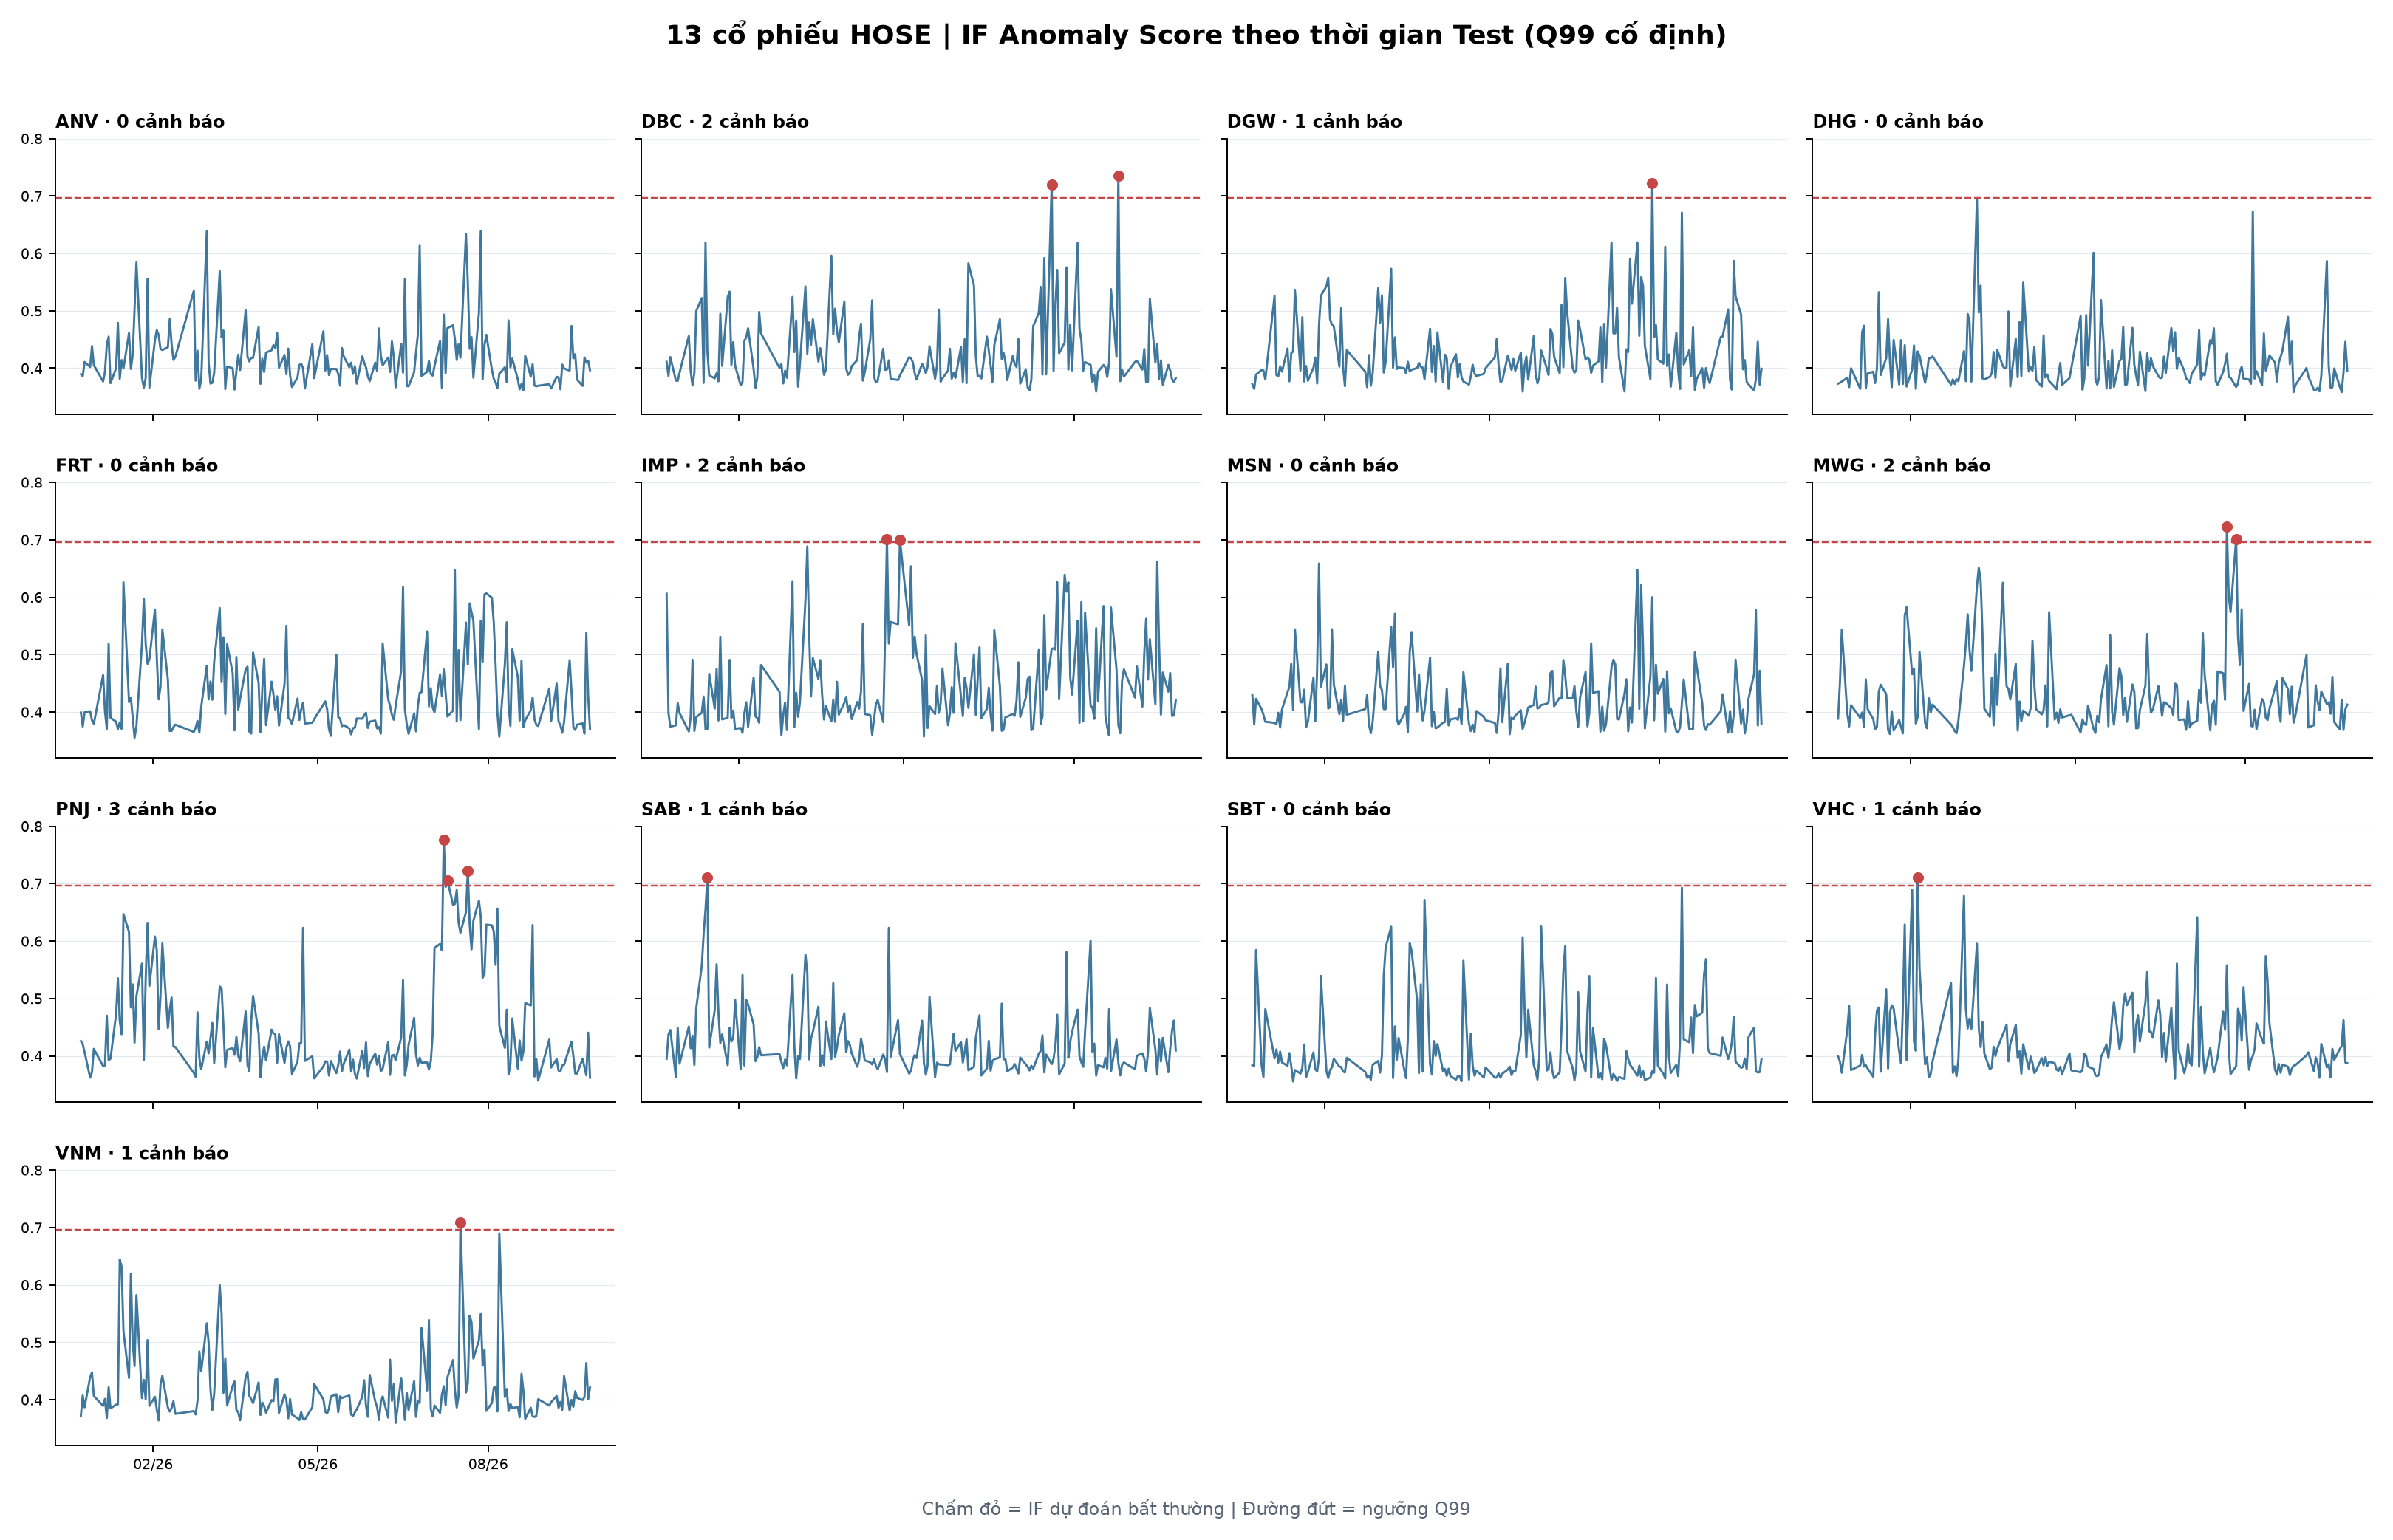

**09_feature_signature_IF13.png**

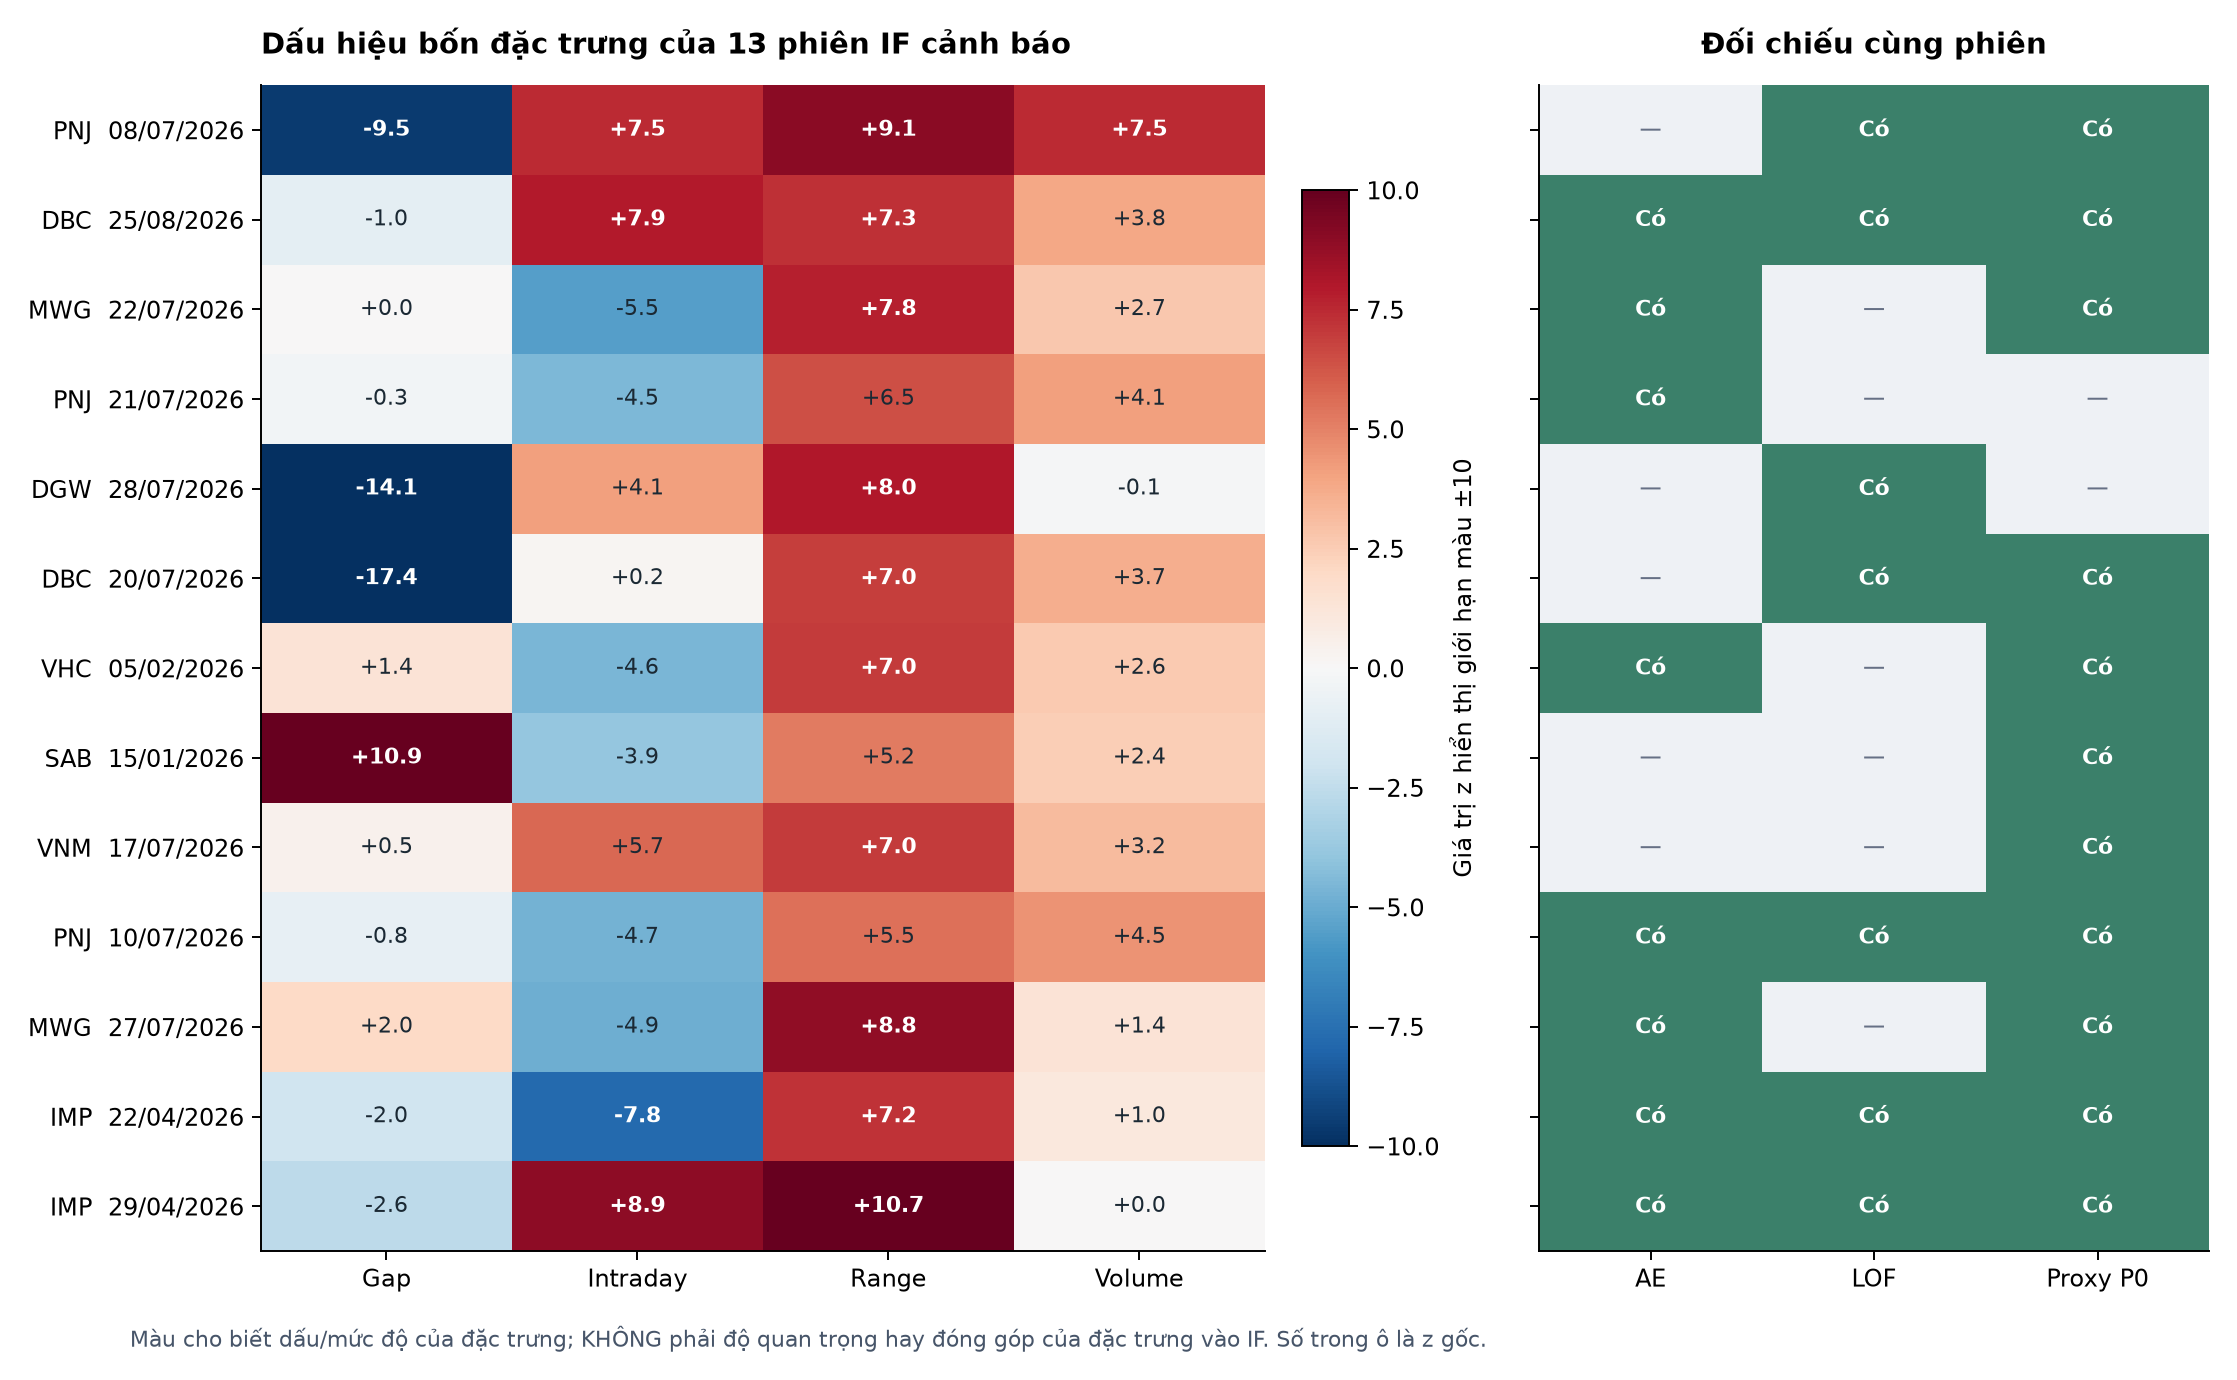

**09_consensus_overlap_matrix.png**

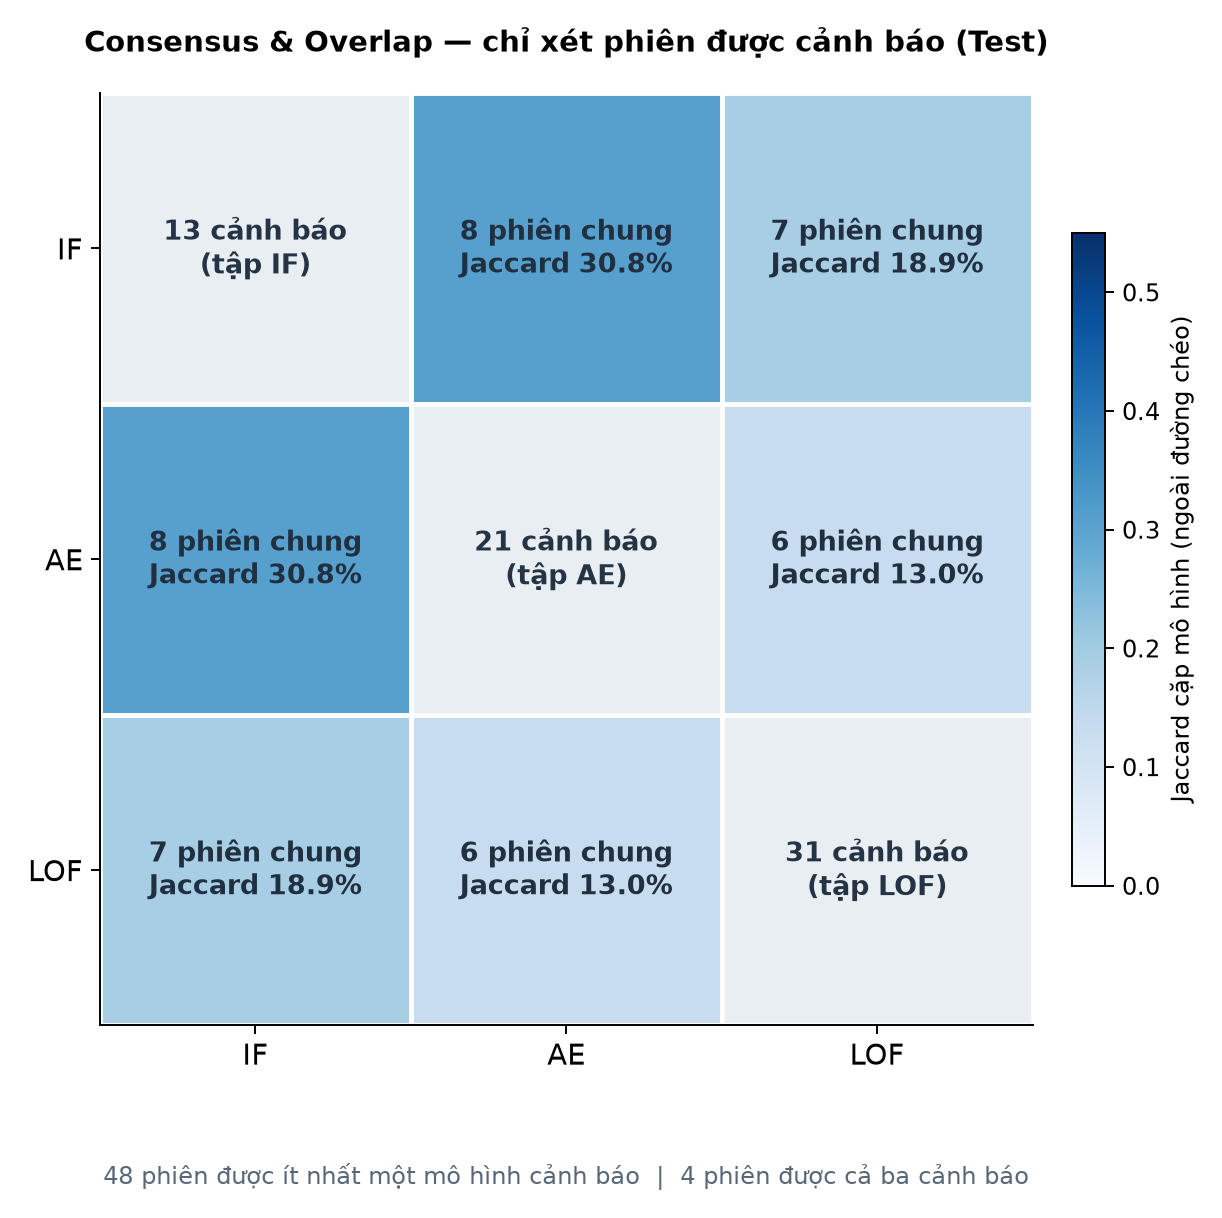

**09_score_distributions_valcal_vs_test.png**

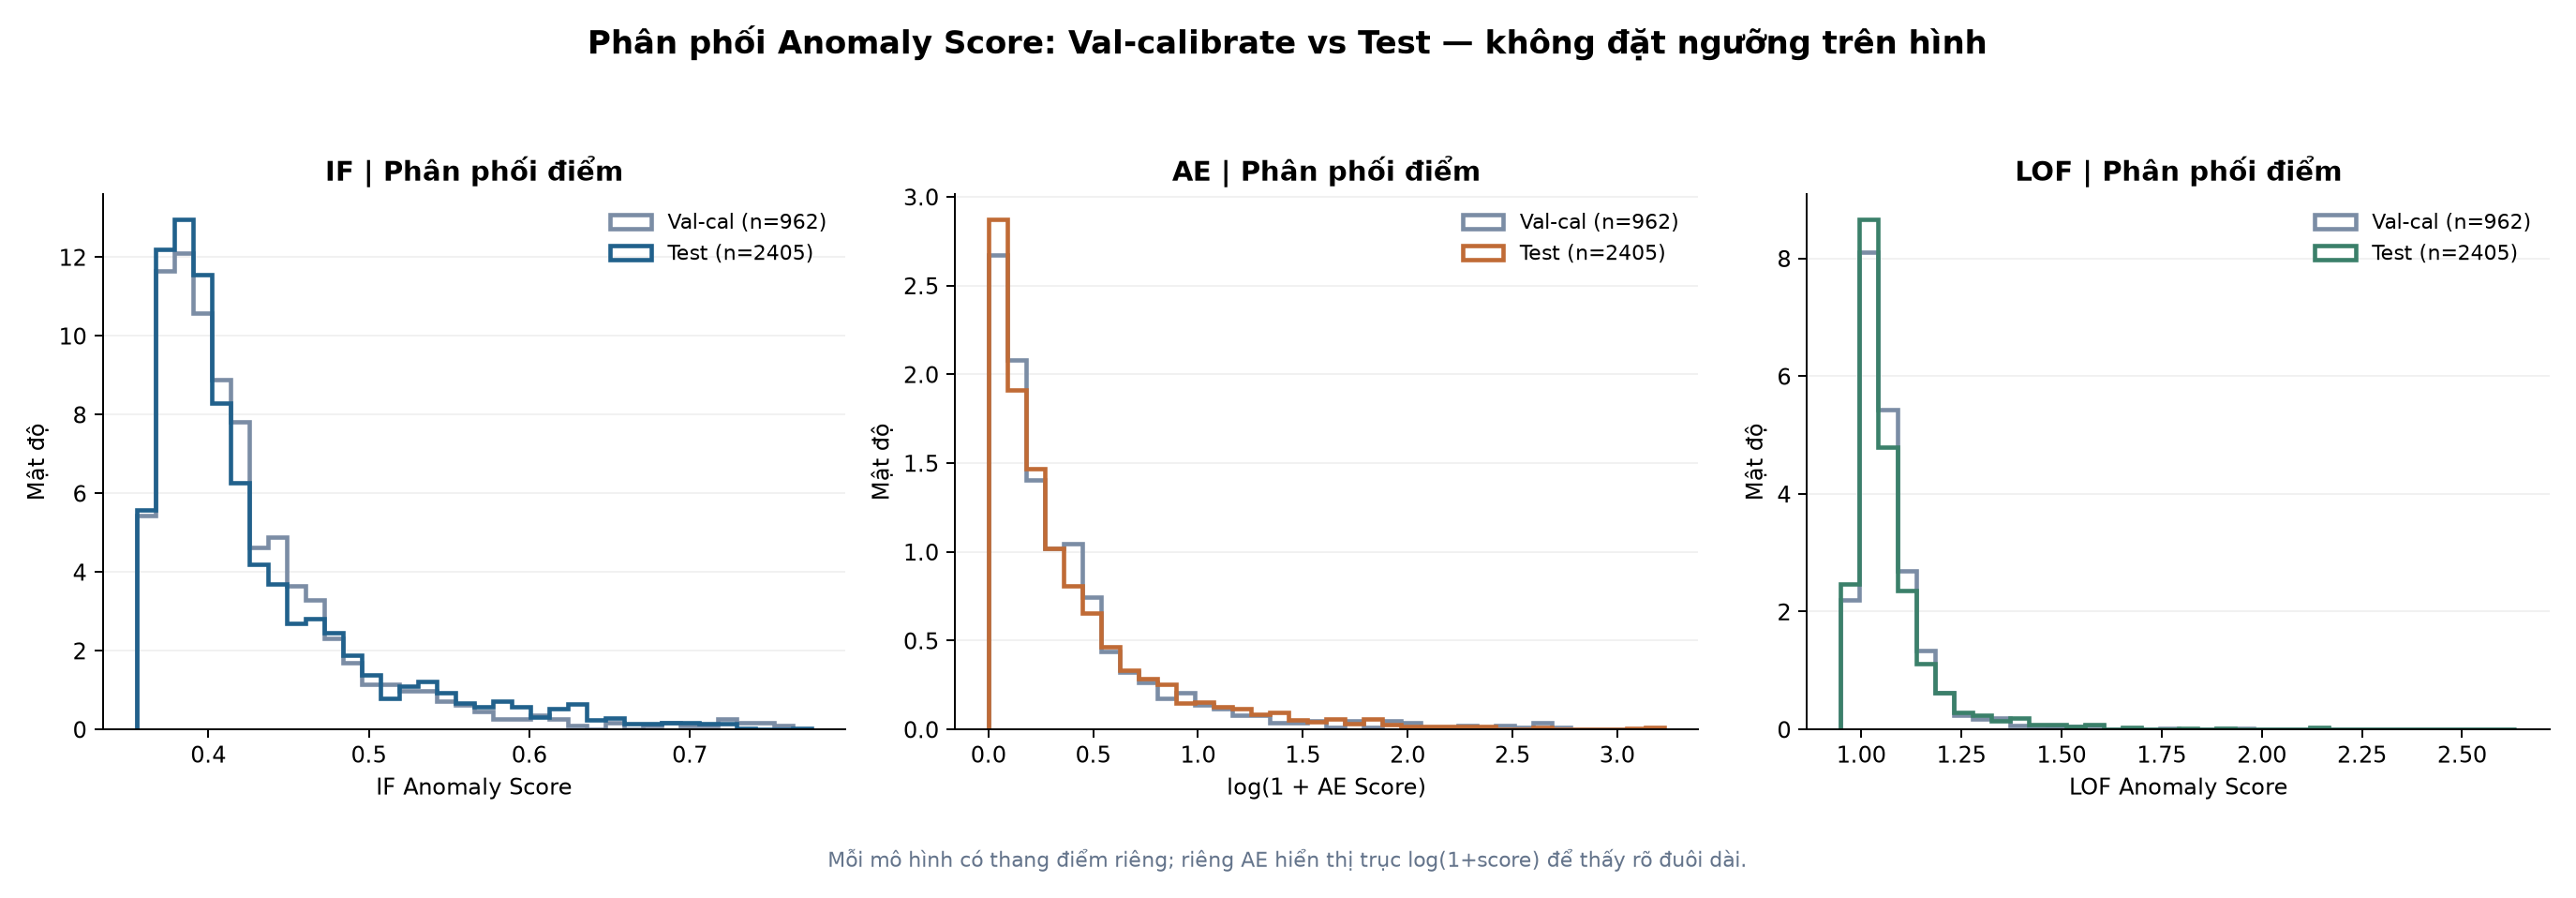

Đã xuất đủ hình chi tiết. Xem 13 timeline và 8 case studies trong thư mục figures/.


In [5]:
from IPython.display import display, Image, Markdown
from pathlib import Path
FIG_DIR = Path(RESULT['figures'])
preview = [
    FIG_DIR/'01_company_timelines'/'09_timelines_13_tickers_overview.png',
    FIG_DIR/'02_feature_signature'/'09_feature_signature_IF13.png',
    FIG_DIR/'03_consensus'/'09_consensus_overlap_matrix.png',
    FIG_DIR/'05_score_distribution'/'09_score_distributions_valcal_vs_test.png',
]
for path in preview:
    assert path.is_file(), f'Thiếu hình: {path}'
    display(Markdown('**' + path.name + '**'))
    display(Image(filename=str(path), width=950))
print('Đã xuất đủ hình chi tiết. Xem 13 timeline và 8 case studies trong thư mục figures/.')